<a href="https://colab.research.google.com/github/fahadahmad84-design/Quantum-Computing-Labs/blob/main/notebook/Week_09_QC_M34099_Student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Laboratory: NISQ Noise and Readout Mitigation

[![View in GitHub](https://img.shields.io/badge/View%20in-GitHub-black?logo=github)](https://github.com/fahadahmad84-design/Quantum-Computing-Labs/blob/main/notebooks/Week_09_QC_M34099_Student.ipynb)

**M34099 Quantum Computing: Level 7 (2026/27)**

This laboratory contains three basic tasks:

1. observe finite-shot sampling variation;
2. calibrate and mitigate one-qubit readout error; and
3. evaluate whether mitigation improved the result.

The example uses one qubit so that every probability and error measure can be checked by hand.

> **Saving your work:** In Colab, select **File > Save a copy in Drive** before editing.


## Set up Google Colab

Run the installation cell once. If Colab requests a restart, select **Runtime > Restart session**, then continue from the imports cell.


In [ ]:
# Install Qiskit, the Aer simulator, IBM Runtime, and drawing support.
%pip install -q "qiskit[visualization]" qiskit-aer qiskit-ibm-runtime pylatexenc


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [ ]:
# Import NumPy for arrays and calculations.
import numpy as np
# Import the Qiskit circuit and transpiler tools.
from qiskit import QuantumCircuit, transpile
# Import the local simulator.
from qiskit_aer import AerSimulator
# Import the readout-noise tools.
from qiskit_aer.noise import NoiseModel, ReadoutError
# Import the histogram plotting function.
from qiskit.visualization import plot_histogram

# Set the number of repeated measurements.
SHOTS = 4096
# Set a fixed seed for repeatable simulator results.
SEED = 34099
# Create the ideal simulator.
ideal_simulator = AerSimulator()

# Qiskit stores prepared states in rows and reported states in columns.
qiskit_readout_matrix = [[0.90, 0.10], [0.20, 0.80]]
# Create an empty noise model.
noise_model = NoiseModel()
# Add asymmetric readout error to qubit zero.
noise_model.add_readout_error(ReadoutError(qiskit_readout_matrix), [0])
# Create the noisy simulator.
noisy_simulator = AerSimulator(noise_model=noise_model)

print("Setup complete.")


Setup complete.


## Helper functions

The first function runs a measured circuit. The second converts counts into the ordered probability vector $[P(0),P(1)]$.


In [ ]:
# Create a function that runs a circuit and returns measurement counts.
def run_counts(circuit, backend, shots=SHOTS, run_seed=SEED):
    # Convert the circuit for the selected backend.
    compiled = transpile(circuit, backend, seed_transpiler=SEED)
    # Run the compiled circuit.
    job = backend.run(compiled, shots=shots, seed_simulator=run_seed)
    # Return the measurement counts.
    return job.result().get_counts()

# Create a function that returns probabilities in the order zero, one.
def counts_to_probabilities(counts, shots=SHOTS):
    # Estimate the probability of zero.
    probability_zero = counts.get("0", 0) / shots
    # Estimate the probability of one.
    probability_one = counts.get("1", 0) / shots
    # Return the ordered probability vector.
    return np.array([probability_zero, probability_one], dtype=float)


## Task 1: Observe finite-shot sampling variation

The H gate prepares equal ideal probabilities:

$$H|0\rangle=(|0\rangle+|1\rangle)/\sqrt{2}.$$

Run the same ideal circuit with five random seeds. The counts will vary, but the estimated probabilities should remain close to $[0.50,0.50]$.


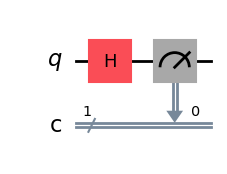

34099 {'1': 2034, '0': 2062} [0.50341797 0.49658203]
34100 {'0': 2069, '1': 2027} [0.50512695 0.49487305]
34101 {'1': 2032, '0': 2064} [0.50390625 0.49609375]
34102 {'1': 2047, '0': 2049} [0.50024414 0.49975586]
34103 {'1': 2033, '0': 2063} [0.50366211 0.49633789]


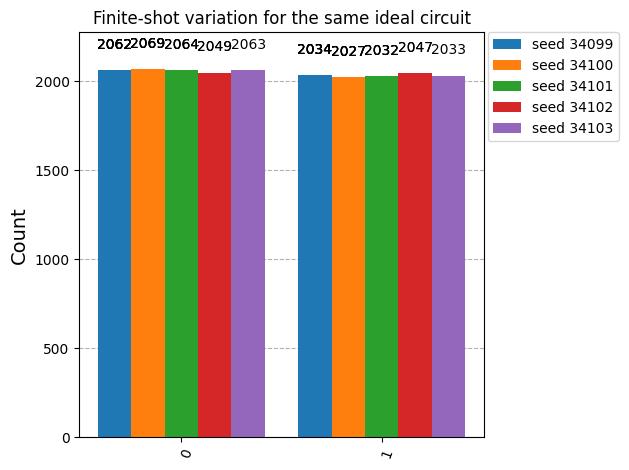

In [ ]:
# Create one qubit and one classical bit.
target_circuit = QuantumCircuit(1, 1)
# Prepare an equal superposition.
target_circuit.h(0)
# Measure in the Z basis.
target_circuit.measure(0, 0)
# Draw the target circuit.
display(target_circuit.draw("mpl"))

# Create an empty dictionary for the five histograms.
sampling_counts = {}

# Repeat the ideal experiment with five seeds.
for offset in range(5):
    # Select a different simulator seed.
    current_seed = SEED + offset
    # Run the circuit.
    counts = run_counts(target_circuit, ideal_simulator, run_seed=current_seed)
    # Convert counts into probabilities.
    probabilities = counts_to_probabilities(counts)
    # Store the counts for plotting.
    sampling_counts[f"seed {current_seed}"] = counts
    # Display the result.
    print(current_seed, counts, probabilities)

# Plot the five finite-shot distributions.
display(plot_histogram(
    list(sampling_counts.values()),
    legend=list(sampling_counts.keys()),
    title="Finite-shot variation for the same ideal circuit",
))


### Result

Changing the seed changes the sampled counts, not the ideal probabilities. More shots reduce this random variation, but they do not remove a systematic hardware bias.


## Task 2: Calibrate and mitigate readout error

Prepare known 0 and 1 states. The calibration columns estimate

$$P(\text{reported outcome}\mid\text{prepared state}).$$


In [ ]:
# Create a function that estimates one calibration column.
def calibration_column(prepared_state):
    # Create one qubit and one classical bit.
    circuit = QuantumCircuit(1, 1)
    # Apply X only when preparing state one.
    if prepared_state == 1:
        circuit.x(0)
    # Measure the known state.
    circuit.measure(0, 0)
    # Run with readout noise.
    counts = run_counts(
        circuit,
        noisy_simulator,
        run_seed=SEED + prepared_state,
    )
    # Return the ordered probabilities.
    return counts_to_probabilities(counts)

# Estimate the column for prepared zero.
p_report_given_zero = calibration_column(0)
# Estimate the column for prepared one.
p_report_given_one = calibration_column(1)
# Combine the two columns into the confusion matrix.
A = np.column_stack([p_report_given_zero, p_report_given_one])

print("Estimated confusion matrix A:")
print(A)
print("Column sums:", A.sum(axis=0))


Estimated confusion matrix A:
[[0.90185547 0.20947266]
 [0.09814453 0.79052734]]
Column sums: [1. 1.]


Each column should sum to approximately 1. Now run the H circuit under ideal and noisy conditions, then solve $A\hat p=q$.


In [ ]:
# Run the target circuit without hardware noise.
ideal_counts = run_counts(target_circuit, ideal_simulator)
# Run the same circuit with readout noise.
noisy_counts = run_counts(target_circuit, noisy_simulator)
# Convert the ideal counts into probabilities.
p_ideal = counts_to_probabilities(ideal_counts)
# Convert the noisy counts into probabilities.
q_noisy = counts_to_probabilities(noisy_counts)

# Solve the calibrated linear system.
p_mitigated = np.linalg.solve(A, q_noisy)
# Remove any small negative values caused by finite sampling.
p_mitigated = np.clip(p_mitigated, 0.0, None)
# Renormalise the corrected probabilities.
p_mitigated = p_mitigated / p_mitigated.sum()

print("Ideal probabilities:", p_ideal)
print("Raw noisy probabilities:", q_noisy)
print("Mitigated probabilities:", p_mitigated)


Ideal probabilities: [0.50341797 0.49658203]
Raw noisy probabilities: [0.55224609 0.44775391]
Mitigated probabilities: [0.49506347 0.50493653]


### Result

The raw noisy distribution should show an asymmetric shift. Linear mitigation uses the calibrated confusion matrix to estimate a distribution closer to the ideal result. This step corrects only the modelled readout process.


## Task 3: Evaluate the mitigation result

Use total-variation distance

$$\operatorname{TVD}(p,q)=\frac12\sum_i|p_i-q_i|$$

and the Z expectation $\langle Z\rangle=P(0)-P(1)$.


In [ ]:
# Create a function that calculates total-variation distance.
def tvd(p, q):
    # Convert the inputs into arrays and sum absolute differences.
    return 0.5 * np.sum(np.abs(np.asarray(p) - np.asarray(q)))

# Create a function that calculates the Z expectation.
def z_expectation(probabilities):
    # Subtract the probability of one from the probability of zero.
    return probabilities[0] - probabilities[1]

# Calculate raw and mitigated distribution errors.
raw_tvd = tvd(p_ideal, q_noisy)
mitigated_tvd = tvd(p_ideal, p_mitigated)
# Calculate raw and mitigated expectation errors.
raw_z_error = abs(z_expectation(q_noisy) - z_expectation(p_ideal))
mitigated_z_error = abs(z_expectation(p_mitigated) - z_expectation(p_ideal))

print(f"Raw TVD = {raw_tvd:.4f}")
print(f"Mitigated TVD = {mitigated_tvd:.4f}")
print(f"Raw Z-expectation error = {raw_z_error:.4f}")
print(f"Mitigated Z-expectation error = {mitigated_z_error:.4f}")


Raw TVD = 0.0488
Mitigated TVD = 0.0084
Raw Z-expectation error = 0.0977
Mitigated Z-expectation error = 0.0167


### Interpretation questions

1. Did mitigation reduce both error measures in this run?
2. What extra circuit executions were required for calibration?
3. Why does this result not show that gate noise or decoherence has been removed?
4. What should be repeated before making a general claim?

### PBL and coursework record

Record the shots, seeds, calibration matrix, raw and mitigated distributions, both error measures and calibration overhead. Write one paragraph using this order: claim, evidence, interpretation, limitation and link to the research question.

## References

- Qiskit Aer, *Building noise models*: https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html
- IBM Quantum Learning, *Foundations of quantum error correction*: https://quantum.cloud.ibm.com/learning/en/courses/foundations-of-quantum-error-correction

Accessed 12 August 2026.
